<a href="https://colab.research.google.com/github/Nihat0311/Computer-Vision/blob/main/Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install torch torchvision albumentations opencv-python tqdm scikit-learn

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"nihat123","key":"2e3f5b2d33b88404948580c90d1b8ffd"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d debeshjha1/kvasirseg -p ./data
!unzip -q ./data/kvasirseg.zip -d ./data/kvasirseg

Dataset URL: https://www.kaggle.com/datasets/debeshjha1/kvasirseg
License(s): copyright-authors
100% 144M/144M [00:01<00:00, 140MB/s]



In [ ]:
import os
import cv2
import numpy as np
from glob import glob
from tqdm import tqdm
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import albumentations as A
from albumentations.pytorch import ToTensorV2

In [ ]:
DATA_DIR='/content/data/kvasirseg/Kvasir-SEG/Kvasir-SEG'
IMAGE_DIR=os.path.join(DATA_DIR, 'images')
MASK_DIR=os.path.join(DATA_DIR, 'masks')

image_path=sorted(glob(os.path.join(IMAGE_DIR, '*')))
masks_paths=sorted(glob(os.path.join(MASK_DIR, '*')))

device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [ ]:
train_images, val_images, train_masks, val_masks=train_test_split(image_path, masks_paths, test_size=0.2, random_state=42)

In [ ]:
train_transform = A.Compose([
        A.Resize(128,128),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.2),
        A.RandomRotate90(p=0.5),
        A.ShiftScaleRotate(
            shift_limit=0.05,
            scale_limit=0.1,
            rotate_limit=15,
            p=0.5,
        ),
        A.Normalize(
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225),
        ),
        ToTensorV2(),
    ])

val_transform = A.Compose([
        A.Resize(128,128),
        A.Normalize(
            mean=(0.485, 0.456, 0.406),
            std=(0.229, 0.224, 0.225),
        ),
        ToTensorV2(),
    ])

/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [ ]:
class MedicalSegmentationDataset(Dataset):
    def __init__(self, image_paths, mask_paths, transform=None):
      self.image_paths=image_paths
      self.mask_paths=mask_paths
      self.transform=transform

    def __len__(self):
      return len(self.image_paths)

    def __getitem__(self, idx):
      image=cv2.imread(self.image_paths[idx])
      image=cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
      mask=cv2.imread(self.mask_paths[idx], cv2.IMREAD_GRAYSCALE)
      mask=(mask>127).astype('float32')
      if self.transform:
        augmented=self.transform(image=image, mask=mask)
        image=augmented['image']
        mask=augmented['mask']
      mask=mask.unsqueeze(0)
      return image, mask

In [ ]:
train_dataset=MedicalSegmentationDataset(train_images, train_masks, transform=train_transform)
val_dataset=MedicalSegmentationDataset(val_images, val_masks, transform=val_transform)

In [ ]:
train_loader=DataLoader(train_dataset, batch_size=2, shuffle=True, num_workers=0,pin_memory=False)
val_loader=DataLoader(val_dataset, batch_size=2, shuffle=False, num_workers=0,pin_memory=False)

In [ ]:
class DoubleConv(nn.Module):
  def __init__(self, in_channels, out_channels):
    super().__init__()

    self.block=nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1,bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1,bias=False),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    )
  def forward(self,x):
    return self.block(x)

In [ ]:
class UNet(nn.Module):
  def __init__(self, in_channels=3, out_channels=1,features=[64,128,256,512]):
    super().__init__()

    self.downs=nn.ModuleList()
    self.ups=nn.ModuleList()
    self.pool=nn.MaxPool2d(kernel_size=2, stride=2)

    for feature in features:
      self.downs.append(DoubleConv(in_channels, feature))
      in_channels=feature

    self.bottleneck=DoubleConv(features[-1], features[-1]*2)


    for feature in reversed(features):
      self.ups.append(
          nn.ConvTranspose2d(
              feature*2, feature, kernel_size=2, stride=2
          )
      )
      self.ups.append(DoubleConv(feature*2, feature))
    self.final_conv=nn.Conv2d(features[0], out_channels, kernel_size=1)
  def forward(self, x):
    skip_connections=[]
    for down in self.downs:
      x=down(x)
      skip_connections.append(x)
      x=self.pool(x)

    x=self.bottleneck(x)
    skip_connections=skip_connections[::-1]
    for idx in range(0, len(self.ups), 2):
      x=self.ups[idx](x)
      skip=skip_connections[idx//2]
      if x.shape!=skip.shape:
        x=torch.nn.functional.interpolate(x,size=skip.shape[2:],mode='bilinear',align_corners=False)
      x=torch.cat((skip, x), dim=1)
      x=self.ups[idx+1](x)
    return self.final_conv(x)

In [ ]:
class DiceLoss(nn.Module):
  def __init__(self, smooth=1e-6):
    super().__init__()
    self.smooth=smooth

  def forward(self, logits,targets):
    probs=torch.sigmoid(logits)
    probs=probs.view(-1)
    targets=targets.view(-1)
    intersection=torch.sum(probs*targets)
    dice=(2.0*intersection+self.smooth)/(probs.sum()+targets.sum()+self.smooth)
    return 1.0-dice

In [ ]:
class FocolLoss(nn.Module):
  def __init__(self, alpha=0.8, gamma=2.0):
    super().__init__()
    self.alpha=alpha
    self.gamma=gamma
    self.bce=nn.BCEWithLogitsLoss(reduction='none')

  def forward(self, logits, targets):
    bce_loss=self.bce(logits, targets)
    probs=torch.sigmoid(logits)
    pt=torch.where(targets==1, probs, 1-probs)
    focal_weight=self.alpha*(1-pt)**self.gamma
    return (focal_weight*bce_loss).mean()

In [ ]:
class DiceFocalLoss(nn.Module):
  def __init__(self,dice_weight=0.5,focal_weight=0.5):
    super().__init__()
    self.dice_weight=dice_weight
    self.focal_weight=focal_weight
    self.dice=DiceLoss()
    self.focal=FocolLoss()
  def forward(self, logits, targets):
    return (self.dice_weight*self.dice(logits, targets)+self.focal_weight*self.focal(logits, targets))

In [ ]:
def dice_score(logits,targets,threshold=0.5,smooth=1e-6):
  probs=torch.sigmoid(logits)
  preds=(probs>threshold).float()
  preds=preds.view(-1)
  targets=targets.view(-1)
  intersection=(preds*targets).sum()
  dice=(2.0*intersection+smooth)/(probs.sum()+targets.sum()+smooth)
  return dice.item()

In [ ]:
def train_one_epoch(model, loader, optimizer, loss_fn, device):
    model.train()

    total_loss = 0.0
    total_dice = 0.0

    for images, masks in tqdm(loader):
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        loss = loss_fn(logits, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        total_dice += dice_score(logits.detach(), masks)

    return total_loss / len(loader), total_dice / len(loader)


def validate(model, loader, loss_fn, device):
    model.eval()

    total_loss = 0.0
    total_dice = 0.0

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device)
            masks = masks.to(device)

            logits = model(images)
            loss = loss_fn(logits, masks)

            total_loss += loss.item()
            total_dice += dice_score(logits, masks)

    return total_loss / len(loader), total_dice / len(loader)

In [ ]:
model=UNet(in_channels=3,out_channels=1,features=[16,32,64]).to(device)
optimizer=torch.optim.AdamW(model.parameters(), lr=1e-4,weight_decay=1e-4)
loss_fn=DiceFocalLoss(dice_weight=0.5,focal_weight=0.5)

In [ ]:
best_dice = 0.0
epochs = 20

for epoch in range(epochs):
    train_loss, train_dice = train_one_epoch(
        model,
        train_loader,
        optimizer,
        loss_fn,
        device,
    )

    val_loss, val_dice = validate(
        model,
        val_loader,
        loss_fn,
        device,
    )

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Dice: {train_dice:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Dice: {val_dice:.4f}"
    )

    if val_dice > best_dice:
        best_dice = val_dice
        torch.save(model.state_dict(), "best_unet_kvasir_seg.pth")
        print(f"Saved best model with Dice: {best_dice:.4f}")

100%|██████████| 400/400 [00:09<00:00, 43.25it/s]


Epoch [1/20] Train Loss: 0.3835 Train Dice: 0.3558 Val Loss: 0.3715 Val Dice: 0.3782
Saved best model with Dice: 0.3782


100%|██████████| 400/400 [00:08<00:00, 48.86it/s]


Epoch [2/20] Train Loss: 0.3589 Train Dice: 0.3995 Val Loss: 0.3482 Val Dice: 0.4132
Saved best model with Dice: 0.4132


100%|██████████| 400/400 [00:07<00:00, 53.25it/s]


...

Epoch [18/20] Train Loss: 0.2181 Train Dice: 0.6987 Val Loss: 0.2133 Val Dice: 0.6993


100%|██████████| 400/400 [00:08<00:00, 47.85it/s]


Epoch [19/20] Train Loss: 0.2144 Train Dice: 0.7027 Val Loss: 0.1974 Val Dice: 0.7341
Saved best model with Dice: 0.7341


100%|██████████| 400/400 [00:08<00:00, 48.42it/s]


Epoch [20/20] Train Loss: 0.2098 Train Dice: 0.7168 Val Loss: 0.1991 Val Dice: 0.7288


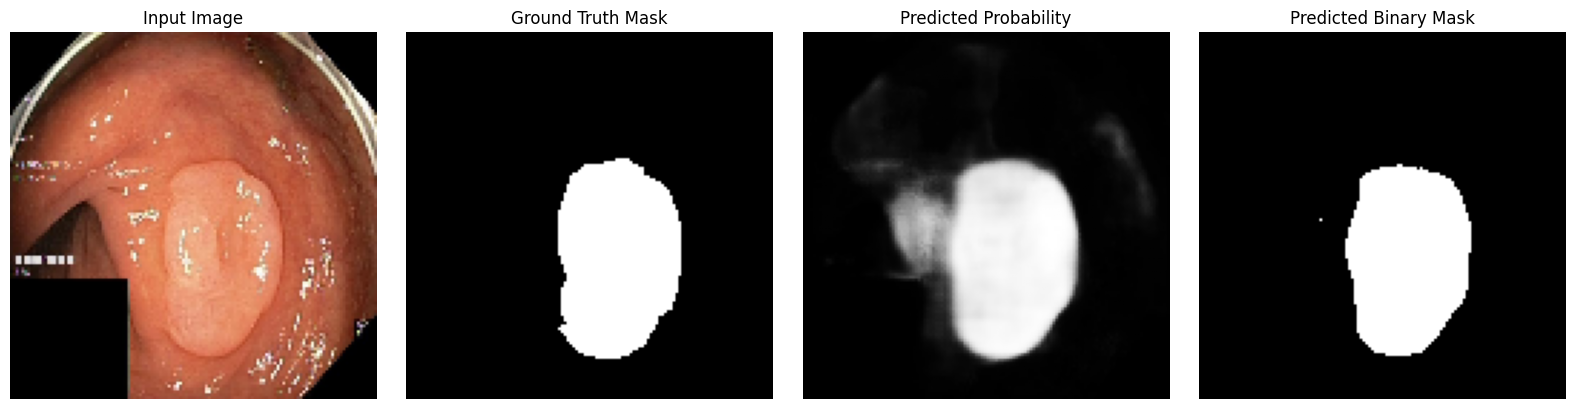

In [ ]:
model.load_state_dict(torch.load("best_unet_kvasir_seg.pth", map_location=device))
model.eval()

image, mask = val_dataset[0]

with torch.no_grad():
    logits = model(image.unsqueeze(0).to(device))   # [1, C, H, W]
    prob = torch.sigmoid(logits)
    pred = (prob > 0.8).float()

image_np = image.permute(1, 2, 0).cpu().numpy()

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image_np = image_np * std + mean
image_np = np.clip(image_np, 0, 1)

mask_np = mask.squeeze().cpu().numpy()
pred_np = pred.squeeze().cpu().numpy()
prob_np = prob.squeeze().cpu().numpy()

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.title("Input Image")
plt.imshow(image_np)
plt.axis("off")

plt.subplot(1, 4, 2)
plt.title("Ground Truth Mask")
plt.imshow(mask_np, cmap="gray")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.title("Predicted Probability")
plt.imshow(prob_np, cmap="gray")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.title("Predicted Binary Mask")
plt.imshow(pred_np, cmap="gray")
plt.axis("off")

plt.tight_layout()
plt.show()

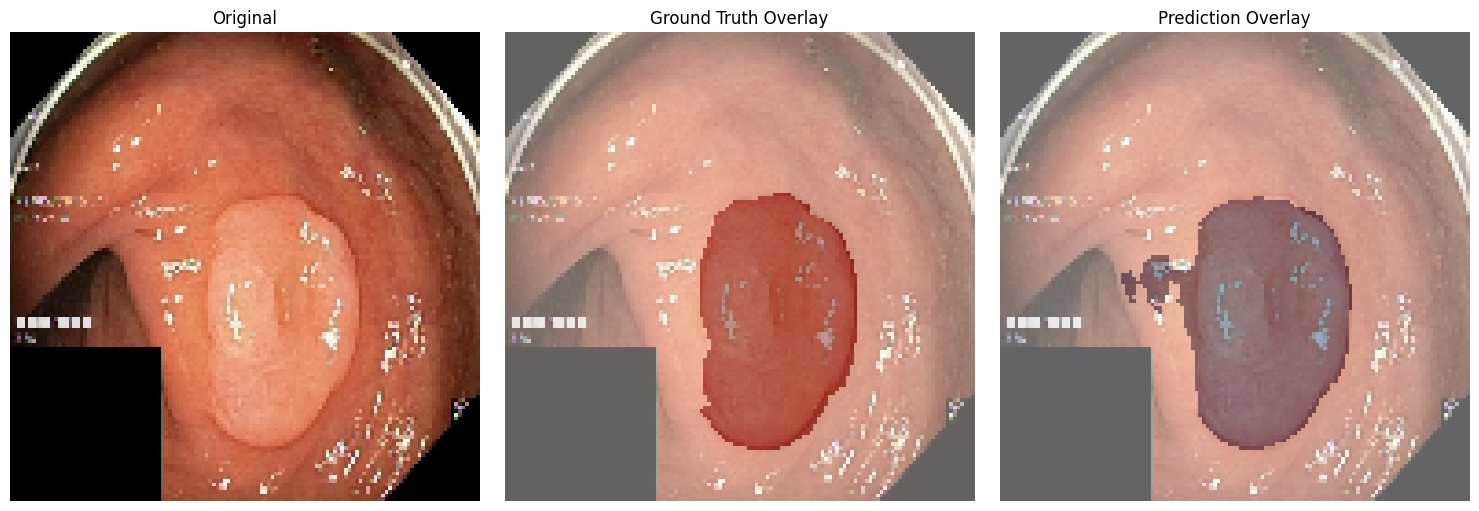

In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title("Original")
plt.imshow(image_np)
plt.axis("off")

plt.subplot(1, 3, 2)
plt.title("Ground Truth Overlay")
plt.imshow(image_np)
plt.imshow(mask_np, cmap="Reds", alpha=0.4)
plt.axis("off")

plt.subplot(1, 3, 3)
plt.title("Prediction Overlay")
plt.imshow(image_np)
plt.imshow((prob_np > 0.65), cmap="Blues", alpha=0.4)
plt.axis("off")

plt.tight_layout()
plt.show()

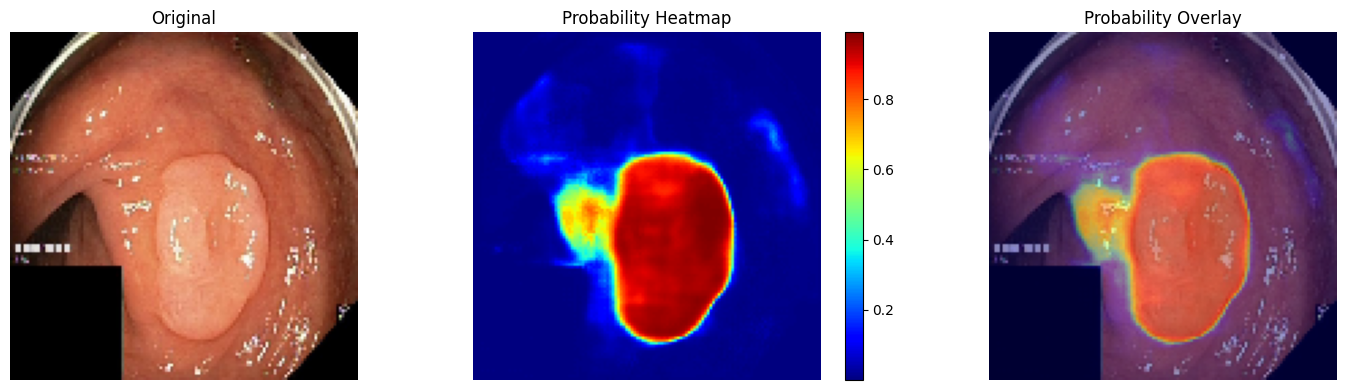

In [ ]:
prob_np = prob.squeeze().cpu().numpy()

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(image_np)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(prob_np, cmap="jet")
plt.title("Probability Heatmap")
plt.axis("off")
plt.colorbar()

plt.subplot(1, 3, 3)
plt.imshow(image_np)
plt.imshow(prob_np, cmap="jet", alpha=0.4)
plt.title("Probability Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

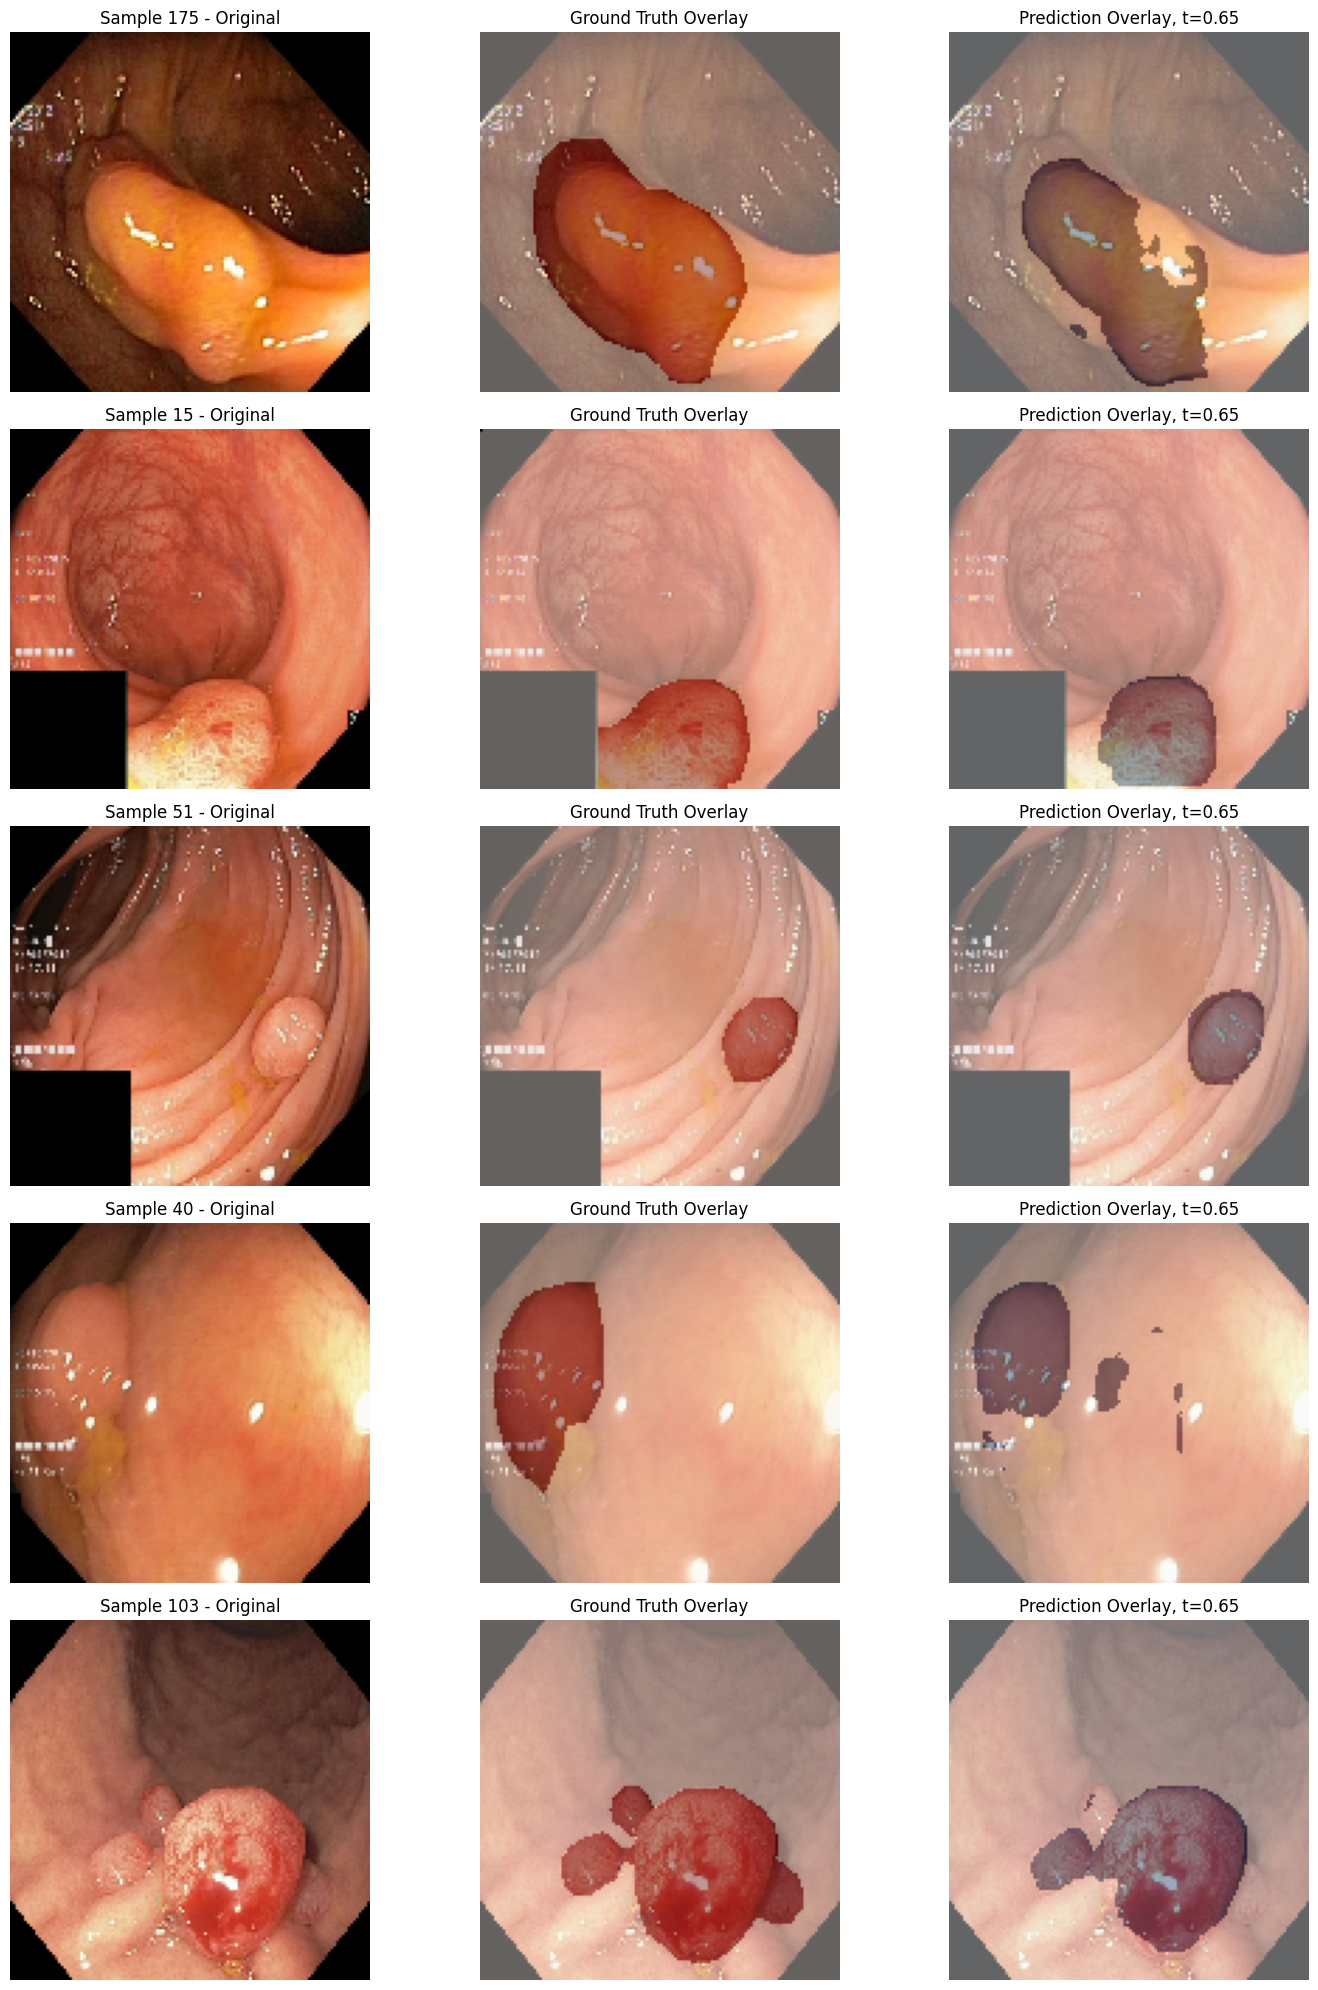

In [ ]:
import random
import torch
import numpy as np
import matplotlib.pyplot as plt

model.load_state_dict(torch.load("best_unet_kvasir_seg.pth", map_location=device))
model.eval()

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

threshold = 0.65

indices = random.sample(range(len(val_dataset)), 5)

plt.figure(figsize=(15, 20))

for row, idx in enumerate(indices):
    image, mask = val_dataset[idx]

    with torch.no_grad():
        logits = model(image.unsqueeze(0).to(device))
        prob = torch.sigmoid(logits)
        pred = (prob > threshold).float()

    # Image denormalize
    image_np = image.permute(1, 2, 0).cpu().numpy()
    image_np = image_np * std + mean
    image_np = np.clip(image_np, 0, 1)

    mask_np = mask.squeeze().cpu().numpy()
    pred_np = pred.squeeze().cpu().numpy()

    #  Original
    plt.subplot(5, 3, row * 3 + 1)
    plt.imshow(image_np)
    plt.title(f"Sample {idx} - Original")
    plt.axis("off")

    #  Ground Truth Overlay
    plt.subplot(5, 3, row * 3 + 2)
    plt.imshow(image_np)
    plt.imshow(mask_np, cmap="Reds", alpha=0.4)
    plt.title("Ground Truth Overlay")
    plt.axis("off")

    #  Prediction Overlay
    plt.subplot(5, 3, row * 3 + 3)
    plt.imshow(image_np)
    plt.imshow(pred_np, cmap="Blues", alpha=0.4)
    plt.title(f"Prediction Overlay, t={threshold}")
    plt.axis("off")

plt.tight_layout()
plt.show()

(np.float64(-0.5), np.float64(127.5), np.float64(127.5), np.float64(-0.5))

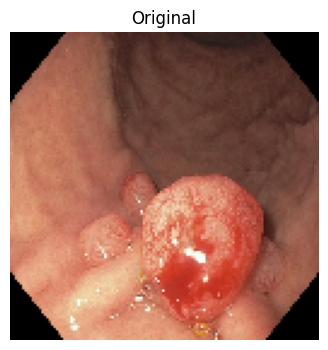

In [ ]:
prob_np = prob.squeeze().cpu().numpy()

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(image_np)
plt.title("Original")
plt.axis("off")